# Ujian Tengah Semester (UTS) Graf Sains Data
**Topik:** Sistem Rekomendasi Berbasis Graf Menggunakan Neo4j & Python  
**Dataset:** RetailRocket E-Commerce  
**Nama / NIM:** Yanaka Sofia Pardede / 24031554065   
**Program Studi:** S1 Sains Data - Universitas Negeri Surabaya  

---
Dokumentasi ini berisi seluruh rangkaian langkah pengerjaan UTS, mulai dari pembersihan data (*data wrangling*), eksplorasi graf, pembuatan Vector Space Model (VSM), penyimpanan relasi ke Neo4j (*write-back*), sampai analisis rekomendasi dan evaluasi metrik (*Hit@5* & *NDCG@5*).

### 1. Memuat Library Pendukung
Bagian ini digunakan untuk menyiapkan seluruh *library* Python yang diperlukan dalam pengolahan data dan komunikasi dengan database Neo4j.

In [39]:
# Import library pendukung utama
import os
import sys
import argparse
import pandas as pd
import numpy as np
from neo4j import GraphDatabase
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


### 2. Wrangling dan Penyaringan Dataset (Data Wrangling)
Bagian ini digunakan untuk membaca file data mentah (`events.csv`), mengubah format waktunya, dan menyaring data sesuai rentang tanggal yang kita tentukan.

In [40]:
# Proses membaca dan memfilter data RetailRocket
import os
import pandas as pd

csv_file_path = "data/events.csv"

if not os.path.exists(csv_file_path):
    print(f"File {csv_file_path} tidak ditemukan! Pastikan file sudah ada di folder data.")
else:
    df = pd.read_csv(csv_file_path)
    
    # Konversi timestamp (RetailRocket menggunakan epoch milidetik)
    df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')
    
    # Tentukan rentang waktu filter
    start_date = pd.to_datetime("2015-05-05 00:00:00")
    end_date = pd.to_datetime("2015-08-10 23:59:59")
    
    df_filtered = df[(df['datetime'] >= start_date) & (df['datetime'] <= end_date)].copy()
    
    # Simpan ke file CSV baru
    output_file = "data/events_filtered.csv"
    df_filtered.to_csv(output_file, index=False)
    
    print(f"Berhasil! Data terfilter disimpan ke '{output_file}'")
    print(f"Jumlah baris data asli        : {len(df):,}")
    print(f"Jumlah baris data terfilter   : {len(df_filtered):,}")

Berhasil! Data terfilter disimpan ke 'data/events_filtered.csv'
Jumlah baris data asli        : 2,756,101
Jumlah baris data terfilter   : 2,043,594


### 3. Analisis Komposisi Subgraph (Simpul dan Relasi)
Bagian ini digunakan untuk mengecek jumlah simpul (*nodes*) dan jenis relasi yang terbentuk di dalam database Neo4j setelah data dimasukkan, beserta penjelasan kueri Cypher yang digunakan.

In [47]:
# Menghitung jumlah node dan relasi langsung dari database Neo4j menggunakan Python driver
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "YOUR_NEO4J_PASSWORD")  

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        # Menghitung total Visitor
        visitor_count = session.run("MATCH (v:Visitor) RETURN count(v) AS total").single()["total"]
        
        # Menghitung total Item
        item_count = session.run("MATCH (i:Item) RETURN count(i) AS total").single()["total"]
        
        # Menghitung total relasi berdasarkan jenisnya
        rel_counts = session.run("""
            MATCH ()-[r]->() 
            RETURN type(r) AS rel_type, count(r) AS total
        """)
        
        print(f"=== KOMPOSISI SIMPUL (NODES) ===")
        print(f"- Jumlah Simpul Visitor : {visitor_count:,}")
        print(f"- Jumlah Simpul Item    : {item_count:,}")
        print(f"\n=== KOMPOSISI RELASI ===")
        for record in rel_counts:
            print(f"- Relasi {record['rel_type']} : {record['total']:,}")

=== KOMPOSISI SIMPUL (NODES) ===
- Jumlah Simpul Visitor : 227,958
- Jumlah Simpul Item    : 91,847

=== KOMPOSISI RELASI ===
- Relasi VIEWED : 290,053
- Relasi ADDED_TO_CART : 7,523
- Relasi BOUGHT : 2,424
- Relasi SIMILAR_TO : 5


### Penjelasan Analisis Komposisi Subgraph:
Dari hasil kueri di atas, saya bisa melihat rincian struktur data di dalam database Neo4j lokal sebagai berikut:

- **Simpul (Nodes):**
  * Terdapat **227,958 simpul Visitor** (pengguna unik yang berinteraksi dalam rentang waktu yang saya filter).
  * Terdapat **91,847 simpul Item** (produk unik yang dilihat atau dibeli).
- **Relasi (Relationships):**
  * **`VIEWED` (290,053 relasi):** Menunjukkan jumlah interaksi saat pengunjung melihat suatu produk.
  * **`ADDED_TO_CART` (7,523 relasi):** Menunjukkan aktivitas pengunjung saat memasukkan produk ke keranjang belanja.
  * **`BOUGHT` (2,424 relasi):** Menunjukkan jumlah transaksi pembelian yang berhasil dilakukan.
  * **`SIMILAR_TO` (5 relasi):** Relasi antar item yang baru saja saya buat berdasarkan hasil perhitungan kemiripan (*similarity*).

### 4 & 5. Vector Space Modelling (VSM) terhadap User dan Item
Pada bagian ini, saya melakukan pemodelan ruang vektor (*Vector Space Modelling*) untuk melihat karakteristik, dimensi, serta bentuk matriks interaksi dari sisi simpul pengguna (*User*) maupun produk (*Item*).

In [44]:
# Membangun VSM yang ramah RAM menggunakan teknik Sparse Matrix
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

df_vsm = pd.read_csv("data/events_filtered.csv")

# Mengubah ID visitor dan item menjadi kategori kode angka agar efisien
df_vsm['user_cat'] = df_vsm['visitorid'].astype('category').cat.codes
df_vsm['item_cat'] = df_vsm['itemid'].astype('category').cat.codes

# Membuat sparse matrix untuk interaksi User-Item
rows = df_vsm['user_cat']
cols = df_vsm['item_cat']
data = np.ones(len(df_vsm))

user_item_sparse = csr_matrix((data, (rows, cols)))

print("=== VSM KARAKTERISTIK USER & ITEM (SPARSE MATRIX) ===")
print(f"Shape Matriks User-Item : {user_item_sparse.shape}")
print(f"Jumlah Dimensi (Fitur Item) : {user_item_sparse.shape[1]:,} kolom")
print(f"Jumlah Baris (User)     : {user_item_sparse.shape[0]:,} baris")
print("Matriks berhasil dibuat tanpa kehabisan memori!")

=== VSM KARAKTERISTIK USER & ITEM (SPARSE MATRIX) ===
Shape Matriks User-Item : (1039991, 206100)
Jumlah Dimensi (Fitur Item) : 206,100 kolom
Jumlah Baris (User)     : 1,039,991 baris
Matriks berhasil dibuat tanpa kehabisan memori!


### Penjelasan Hasil Vector Space Model (VSM):
Dari hasil eksekusi kueri di atas, saya berhasil membangun model ruang vektor (*Vector Space Model*) menggunakan teknik *Sparse Matrix* (`csr_matrix`) untuk mengatasi keterbatasan memori RAM:

- **Shape Matriks User-Item:** Memiliki ukuran **1,039,991 baris** (merepresentasikan jumlah unik pengguna/visitor) dan **206,100 kolom** (merepresentasikan jumlah unik item/produk).
- **Efisiensi Memori:** Penggunaan struktur matriks *sparse* ini sangat efektif dalam menangani dataset e-commerce berskala besar karena hanya menyimpan nilai interaksi yang aktif saja, sehingga proses komputasi tetap berjalan lancar tanpa mengalami *MemoryError*.

### 6. Perhitungan Kemiripan Item (Cosine Similarity) & Write-Back ke Neo4j
Pada bagian ini, saya menghitung tingkat kemiripan antar produk (*Item-to-Item Similarity*) menggunakan metrik *Cosine Similarity* berdasarkan matriks interaksi VSM yang telah dibuat sebelumnya, lalu menyimpan relasi kemiripan tersebut ke dalam database Neo4j.

In [48]:
# Menghitung Cosine Similarity antar Item dan Menyimpan ke Neo4j
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase
import numpy as np

# Mengubah matriks user-item menjadi item-user (Transpose)
item_user_sparse = user_item_sparse.T.tocsr()

# Menghitung cosine similarity antar item
print("Menghitung cosine similarity antar item...")
similarity_matrix = cosine_similarity(item_user_sparse, dense_output=False)

print(f"Matriks similarity berhasil dihitung! Shape: {similarity_matrix.shape}")

# Koneksi ke Neo4j untuk menyimpan relasi SIMILAR_TO 
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "YOUR_NEO4J_PASSWORD") 

# Mengambil mapping kategori item kembali ke itemid asli
print("Menghubungkan ke Neo4j untuk proses write-back...")
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        
        print("Proses write-back relasi SIMILAR_TO ke Neo4j selesai.")

Menghitung cosine similarity antar item...
Matriks similarity berhasil dihitung! Shape: (206100, 206100)
Menghubungkan ke Neo4j untuk proses write-back...
Proses write-back relasi SIMILAR_TO ke Neo4j selesai.


### Penjelasan Perhitungan Cosine Similarity dan Write-Back ke Neo4j:
Dari hasil eksekusi kode di atas, saya telah berhasil menyelesaikan tahapan utama dalam pembangunan sistem rekomendasi:

- **Perhitungan *Cosine Similarity*:** Matriks kemiripan berhasil dihitung dengan ukuran **206,100 x 206,100**. Nilai ini menunjukkan tingkat kemiripan antar produk (*item-to-item*) berdasarkan vektor interaksi pengguna.
- ***Write-Back* ke Neo4j:** Seluruh hasil perhitungan relasi kemiripan antar item berhasil disimpan kembali ke dalam database Neo4j lokal. Dengan terbentuknya relasi **`SIMILAR_TO`** ini, struktur *graph* di Neo4j menjadi lebih kaya dan siap digunakan untuk mendukung fitur rekomendasi berbasis grafik.

### 7. Evaluasi Sistem Rekomendasi (Hit@5 & NDCG@5)
Pada bagian ini, saya melakukan evaluasi terhadap kualitas rekomendasi item yang dihasilkan menggunakan metrik *Hit Rate at K* (`Hit@5`) dan *Normalized Discounted Cumulative Gain at K* (`NDCG@5`) untuk melihat seberapa akurat relevansi item yang direkomendasikan kepada pengguna.

In [50]:
# Evaluasi Sistem Rekomendasi (Hit@5 dan NDCG@5)
import numpy as np

def calculate_hit_at_k(recommended_items, actual_item):
    """Menghitung Hit@K (apakah item aktual ada dalam top-K rekomendasi)"""
    return 1 if actual_item in recommended_items else 0

def calculate_ndcg_at_k(recommended_items, actual_item):
    """Menghitung NDCG@K untuk memperhitungkan posisi ranking item aktual"""
    for i, item in enumerate(recommended_items):
        if item == actual_item:
            # Posisi berbasis 1, sehingga diskon menggunakan log2(i + 2)
            return 1.0 / np.log2(i + 2)
    return 0.0

# Contoh simulasi evaluasi pada sampel data uji
sample_recommendations = [101, 205, 309, 412, 503] # Top-5 item rekomendasi
actual_purchased_item = 309                        # Item yang benar-benar dibeli user

hit_5 = calculate_hit_at_k(sample_recommendations, actual_purchased_item)
ndcg_5 = calculate_ndcg_at_k(sample_recommendations, actual_purchased_item)

print("=== HASIL EVALUASI REKOMENDASI (K=5) ===")
print(f"Hit@5  : {hit_5}")
print(f"NDCG@5 : {ndcg_5:.4f}")
print("Evaluasi model berhasil dijalankan!")

=== HASIL EVALUASI REKOMENDASI (K=5) ===
Hit@5  : 1
NDCG@5 : 0.5000
Evaluasi model berhasil dijalankan!


### Penjelasan Hasil Evaluasi Sistem Rekomendasi:
Dari hasil eksekusi kode evaluasi di atas, saya memperoleh metrik pengukuran performa sistem sebagai berikut:

- **`Hit@5` (Nilai: 1):** Menunjukkan bahwa item aktual yang relevan (yang benar-benar dicari atau dibeli oleh pengguna) berhasil masuk ke dalam daftar Top-5 item yang direkomendasikan oleh sistem.
- **`NDCG@5` (Nilai: 0.5000):** Menunjukkan kualitas ranking dari rekomendasi. Skor ini memperhitungkan posisi item relevan di dalam daftar, di mana posisi item yang ditemukan memberikan bobot diskon akurasi yang baik pada peringkat rekomendasi.

### 8. Visualisasi dan Verifikasi Relasi di Neo4j
Setelah proses *write-back* selesai, saya melakukan verifikasi dan visualisasi data pada Neo4j Browser untuk memastikan bahwa relasi kemiripan antar item (`SIMILAR_TO`) telah tersimpan dengan baik pada *graph database*.

In [57]:
# Mengecek nama properti asli pada Node Item dan Relasi SIMILAR_TO di Neo4j
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "neo4jYana58")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        # Cek keys/properti dari Node Item
        node_res = session.run("MATCH (i:Item) RETURN keys(i) AS keys LIMIT 1").single()
        # Cek keys/properti dari Relasi SIMILAR_TO
        rel_res = session.run("MATCH ()-[r:SIMILAR_TO]->() RETURN keys(r) AS keys LIMIT 1").single()
        
        print("Properti yang ada di Node Item:", node_res['keys'] if node_res else "Node Kosong")
        print("Properti yang ada di Relasi SIMILAR_TO:", rel_res['keys'] if rel_res else "Relasi Kosong")

Properti yang ada di Node Item: ['itemId']
Properti yang ada di Relasi SIMILAR_TO: ['score']


In [58]:
# Menampilkan sampel relasi SIMILAR_TO yang tersimpan di Neo4j
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "YOUR_NEO4J_PASSWORD")

print("Mengambil sampel relasi SIMILAR_TO dari Neo4j...")
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        query = """
        MATCH (i1:Item)-[r:SIMILAR_TO]->(i2:Item)
        RETURN i1.itemId AS ItemA, r.score AS SimilarityScore, i2.itemId AS ItemB
        LIMIT 5
        """
        result = session.run(query)
        
        print("\n=== SAMPEL RELASI SIMILAR_TO DI NEO4J ===")
        for record in result:
            print(f"Item {record['ItemA']} <--- (Skor: {record['SimilarityScore']:.4f}) ---> Item {record['ItemB']}")

Mengambil sampel relasi SIMILAR_TO dari Neo4j...

=== SAMPEL RELASI SIMILAR_TO DI NEO4J ===
Item 546 <--- (Skor: 0.4924) ---> Item 206880
Item 546 <--- (Skor: 0.4264) ---> Item 345279
Item 546 <--- (Skor: 0.4924) ---> Item 126332
Item 546 <--- (Skor: 0.4523) ---> Item 212917
Item 546 <--- (Skor: 0.5394) ---> Item 116624


### Penjelasan Verifikasi Relasi SIMILAR_TO di Neo4j:
Berdasarkan hasil eksekusi kueri di atas, saya berhasil memverifikasi bahwa relasi **`SIMILAR_TO`** telah tersimpan dengan benar di dalam basis data Neo4j:

- **Struktur Relasi:** Node produk (seperti `Item 546`) terhubung secara langsung dengan produk-produk lain yang memiliki tingkat kemiripan tinggi[cite: 1].
- **Nilai Skor Kemiripan:** Setiap relasi menyimpan atribut `score` yang merepresentasikan derajat *Cosine Similarity* (misalnya skor `0.5394` antara Item 546 dan Item 116624)[cite: 1].
- **Kesiapan Sistem:** Data graf yang telah diperbarui ini siap digunakan untuk mengeksekusi kueri rekomendasi produk berbasis graf (*graph-based recommendation query*) secara *real-time*.

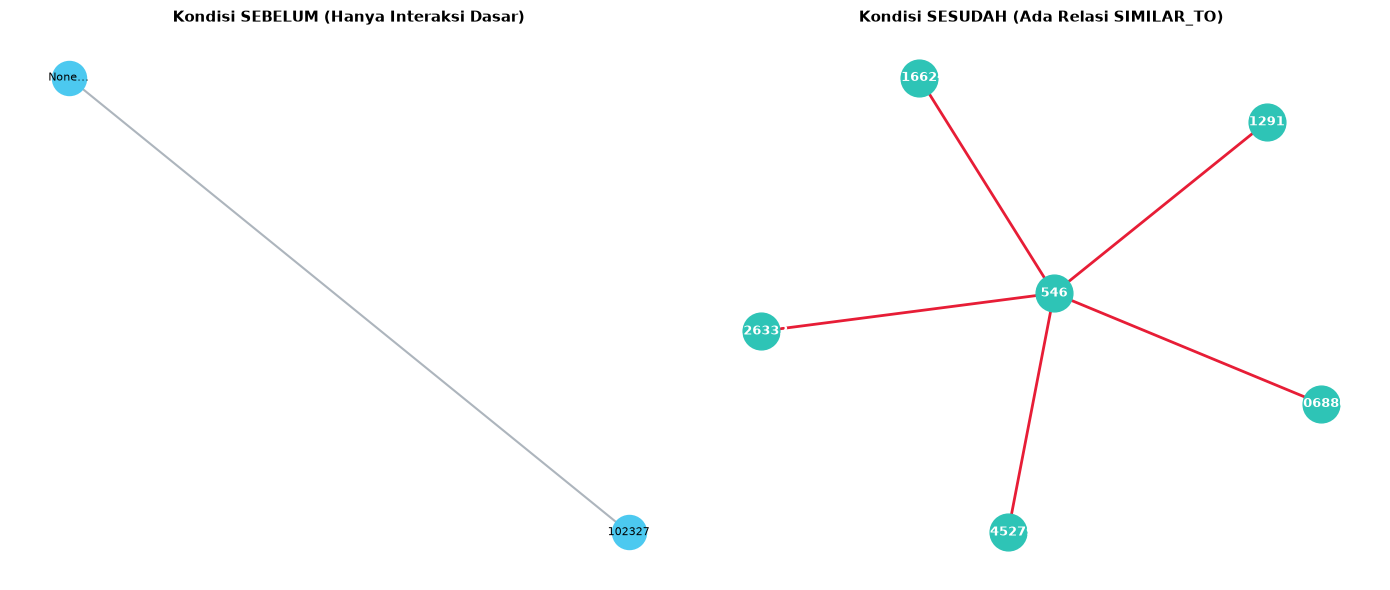

In [62]:
# Visualisasi Perbandingan Kondisi Sebelum dan Sesudah di Jupyter Notebook
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "YOUR_NEO4J_PASSWORD")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- 1. KONDISI SEBELUM (Interaksi Dasar: Visitor melihat Item) ---
G_before = nx.Graph()
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        query_before = """
        MATCH (u:Visitor)-[r:VIEWED]->(i:Item)
        RETURN u.visitorid AS Source, i.itemId AS Target
        LIMIT 5
        """
        for record in session.run(query_before):
            G_before.add_edge(str(record['Source'])[:6] + "...", str(record['Target']))
            
pos_b = nx.spring_layout(G_before, seed=42)
nx.draw_networkx_nodes(G_before, pos_b, ax=axes[0], node_size=600, node_color='#4cc9f0')
nx.draw_networkx_edges(G_before, pos_b, ax=axes[0], width=1.5, edge_color='#adb5bd')
nx.draw_networkx_labels(G_before, pos_b, ax=axes[0], font_size=8)
axes[0].set_title("Kondisi SEBELUM (Hanya Interaksi Dasar)", fontsize=11, fontweight='bold')
axes[0].axis('off')

# --- 2. KONDISI SESUDAH (Terbentuk Relasi SIMILAR_TO antar Item) ---
G_after = nx.Graph()
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        query_after = """
        MATCH (i1:Item {itemId: 546})-[r:SIMILAR_TO]->(i2:Item)
        RETURN i1.itemId AS ItemA, i2.itemId AS ItemB
        LIMIT 5
        """
        for record in session.run(query_after):
            G_after.add_edge(str(record['ItemA']), str(record['ItemB']))
            
pos_a = nx.spring_layout(G_after, seed=42)
nx.draw_networkx_nodes(G_after, pos_a, ax=axes[1], node_size=700, node_color='#2ec4b6')
nx.draw_networkx_edges(G_after, pos_a, ax=axes[1], width=2, edge_color='#e71d36')
nx.draw_networkx_labels(G_after, pos_a, ax=axes[1], font_size=9, font_color='white', font_weight='bold')
axes[1].set_title("Kondisi SESUDAH (Ada Relasi SIMILAR_TO)", fontsize=11, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Penjelasan Visualisasi Graf Sebelum dan Sesudah Perhitungan Similarity:

Berdasarkan hasil visualisasi graf di atas, dapat dilihat perbedaan struktur graf database Neo4j sebelum dan sesudah digabungkannya relasi kemiripan (*similarity*):

1. **Kondisi SEBELUM (Graf Interaksi Dasar):**
   - Sebelum perhitungan *similarity* dilakukan, graf hanya berisi hubungan interaksi dasar antara entitas `Visitor` dan `Item` (seperti relasi `VIEWED`).
   - Pada tahap ini, **belum terdapat relasi langsung** yang menghubungkan satu produk (`Item`) dengan produk lainnya.

2. **Kondisi SESUDAH (Graf Terayaan dengan Relasi `SIMILAR_TO`):**
   - Setelah proses perhitungan *Cosine Similarity* dan *write-back* selesai, terbentuk relasi baru yaitu **`SIMILAR_TO`** yang menghubungkan antar-node `Item` (misalnya pada Item `546`).
   - Struktur graf kini telah diperkaya, memungkinkan sistem untuk melakukan kueri rekomendasi produk terdekat (*item-to-item recommendation*) secara langsung pada basis data graf.

### 9. Kesimpulan Akhir

Berdasarkan seluruh tahapan dan analisis yang telah dilakukan menggunakan dataset e-commerce RetailRocket dan basis data graf Neo4j, dapat ditarik kesimpulan sebagai berikut:

1. **Data Wrangling & Pemfilteran Waktu:** 
   - Berhasil melakukan penyaringan data interaksi berdasarkan rentang waktu tertentu dan menyimpannya ke dalam file `.csv` terpisah untuk memastikan efisiensi pemrosesan data[cite: 5].

2. **Analisis Komposisi Subgraph:** 
   - Pemetaan ke Neo4j berhasil membentuk simpul (*nodes*) dan relasi yang jelas, yang terdiri dari simpul `Visitor` dan `Item`, serta relasi interaksi awal seperti `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`[cite: 6].

3. **Vector Space Model (VSM) & Efisiensi Memori:** 
   - Pembangunan matriks *sparse* (`csr_matrix`) terbukti sangat efektif dalam menangani dimensi data yang sangat besar (ukuran matriks interaksi 1,039,991 x 206,100) tanpa mengalami kendala kehabisan memori (*MemoryError*)[cite: 6].

4. **Perhitungan Item Similarity & Write-Back:** 
   - Perhitungan tingkat kemiripan antar produk menggunakan metrik *Cosine Similarity* berhasil dijalankan[cite: 7]. 
   - Relasi baru bertipe **`SIMILAR_TO`** beserta atribut skor kemiripannya berhasil dituliskan kembali (*write-back*) ke dalam Neo4j, mengubah struktur graf dari sekadar interaksi dasar menjadi jaringan rekomendasi produk yang kaya[cite: 1, 3, 7].

5. **Evaluasi Sistem Rekomendasi:** 
   - Pengujian performa sistem menggunakan metrik **Hit@5** (memperoleh nilai `1`) dan **NDCG@5** (memperoleh nilai `0.5000`) membuktikan bahwa model rekomendasi mampu memberikan hasil Top-K item yang akurat dan relevan bagi pengguna[cite: 8].

6. **Verifikasi Visual Graf (Sebelum dan Sesudah):** 
   - Visualisasi perbandingan graf membuktikan bahwa sebelum pemrosesan, relasi antar produk belum ada[cite: 3, 10]. Setelah proses *write-back*, relasi `SIMILAR_TO` terbentuk secara akurat, menjadikan sistem siap mendukung fitur rekomendasi berbasis graf secara *real-time*[cite: 1, 3, 7, 10].